# DeepTuneIO Analyzer — Contention Analysis — Module 10 Visualization

Notebook de orquestación. La lógica científica está en `Module/contention_analysis.py`.

**Nivel 1:** candidatos DXT A/B/C. **Nivel 2A:** comparación entre modos de acceso. **Nivel 2B:** escalabilidad por procesos.

Los candidatos no equivalen a degradación demostrada. Los trabajos sin DXT no se consideran libres de contención.

## 1. Importar el análisis de contención

In [1]:
from pathlib import Path
import sys, importlib.util
import pandas as pd
from IPython.display import display
MODULE_DIR = (Path.cwd() / "Module").resolve()
MODULE_FILE = MODULE_DIR / "contention_analysis.py"
if not MODULE_FILE.is_file():
    raise FileNotFoundError(f"Abre este notebook desde Contention_Analysis: {MODULE_FILE}")
spec = importlib.util.spec_from_file_location("deeptuneio_contention13", MODULE_FILE)
contention_module = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = contention_module
spec.loader.exec_module(contention_module)
print("Módulo:", MODULE_FILE)

Módulo: F:\NoteBooks\CORA_DR_UAB\Tesis\Scripts\DeepTuneIO\10_Visualization\Contention_Analysis\Module\contention_analysis.py


## 2. Seleccionar aplicación, dataset y escenario

La jerarquía de campañas es la misma que en los notebooks anteriores. Modifica las opciones de tu campaña; no hay rutas de un JobID fijadas en el código.

In [8]:
CAMPAIGNS = {
    "DeepGalaxy": {
        "DG_bw512_f3c5x64": ["lustre_1ost", "lustre_2ost", "lustre_4ost", "nfs_SnGPU_e1"],
    },
    "DLIOv1": {
        "HDF5_64bs": [], "NPZ_64bs": [], "TFRecord_256kts_64bs": [],
    },
    "DeepTuneIO-Training": {},
}
APPLICATION = "DeepGalaxy"
DATASET_GROUP = "DG_bw512_f3c5x64"
SCENARIO = "nfs_SnGPU_e1"
EVENT = "Tesis"
FILE_FORMAT = ".hdf5"
assert APPLICATION in CAMPAIGNS, "Aplicación no configurada"
assert DATASET_GROUP in CAMPAIGNS[APPLICATION], "Dataset no configurado"
options = CAMPAIGNS[APPLICATION][DATASET_GROUP]
if options and SCENARIO not in options:
    raise ValueError(f"Escenario no disponible: {SCENARIO}")
print(APPLICATION, DATASET_GROUP, SCENARIO)

DeepGalaxy DG_bw512_f3c5x64 nfs_SnGPU_e1


## 3. Construir rutas dinámicas

`PROJECT_ROOT` es la raíz de datos experimentales (no la carpeta de notebooks). Los archivos de entrada se descubren dentro de la campaña.

In [9]:
PROJECT_ROOT = Path(r"D:\DL_Experiments\CORA_DR_UAB")
ARTICLE_ROOT = PROJECT_ROOT / EVENT
CAMPAIGN_ROOT = ARTICLE_ROOT / "Data" / APPLICATION / DATASET_GROUP / SCENARIO
OUTPUT_DIR = CAMPAIGN_ROOT / "results" / "Contention_Analysis"
FIGURES_ROOT = CAMPAIGN_ROOT / "results" / "Figures" / "Access_Pattern"
print("Campaign root :", CAMPAIGN_ROOT)
print("Figures root  :", FIGURES_ROOT)
print("Output        :", OUTPUT_DIR)
if not CAMPAIGN_ROOT.is_dir():
    raise FileNotFoundError(f"Campaña inexistente: {CAMPAIGN_ROOT}")

Campaign root : D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepGalaxy\DG_bw512_f3c5x64\nfs_SnGPU_e1
Figures root  : D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepGalaxy\DG_bw512_f3c5x64\nfs_SnGPU_e1\results\Figures\Access_Pattern
Output        : D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepGalaxy\DG_bw512_f3c5x64\nfs_SnGPU_e1\results\Contention_Analysis


## 4. Descubrir CSV de rendimiento y resultados DXT

Comprueba la tabla antes de ejecutar. Se pueden añadir rutas explícitas cuando los CSV estén almacenados fuera de la campaña.

In [15]:
# Patrones de búsqueda de archivos generados por módulos anteriores
PERF_GLOBS = ["results/**/*Perf*.csv", "results/**/*perf*.csv", "processed/**/*Perf*.csv"]
perf_files = sorted({p for pattern in PERF_GLOBS for p in CAMPAIGN_ROOT.glob(pattern) if p.is_file()})
# Si los CSV están en otro directorio, añade rutas completas aquí.
EXTRA_PERF_FILES = []
perf_files = sorted(set(perf_files) | {Path(p) for p in EXTRA_PERF_FILES})
job_dirs = sorted(p for p in FIGURES_ROOT.glob("job_*") if p.is_dir() and any(p.glob("10_contention_three_cases_pairs*.csv")))
print(f"Performance CSVs: {len(perf_files)} | JobIDs DXT: {len(job_dirs)}")
display(pd.DataFrame({"performance_csv": [str(p) for p in perf_files]}))
display(pd.DataFrame({"dxt_job_directory": [str(p) for p in job_dirs]}).head(30))

Performance CSVs: 1 | JobIDs DXT: 8


,performance_csv
0,D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepG...


,dxt_job_directory
0,D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepG...
1,D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepG...
2,D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepG...
3,D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepG...
4,D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepG...
5,D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepG...
6,D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepG...
7,D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepG...


## 5. Seleccionar JobIDs y normalizar modos de acceso

Deja `JOB_IDS = None` para procesar todos los JobIDs disponibles. Los códigos numéricos de modo de acceso no se interpretan sin una correspondencia validada.

In [16]:
JOB_IDS = None  # p. ej. [5333326] o None para todos
MODE_MAP = {"0": "Shared", "1": "Shared + Reload + Shuffle"} if APPLICATION == "DeepGalaxy" else {}  # Solo equivalencias verificadas
if JOB_IDS is not None:
    chosen = {str(j) for j in JOB_IDS}
    job_dirs = [p for p in job_dirs if p.name.removeprefix("job_") in chosen]
print("DXT seleccionados:", len(job_dirs))
if not perf_files:
    raise FileNotFoundError("No se encontraron CSV de rendimiento. Ajusta PERF_GLOBS o EXTRA_PERF_FILES.")
preview = contention_module.load_performance(perf_files, mode_map=MODE_MAP)
cols = [c for c in ["jobid", "application", "scenario", "access_mode_normalized", "nodes", "processes", "io_time_s", "bandwidth_mib_s"] if c in preview]
display(preview[cols].head(25))

DXT seleccionados: 8


,jobid,application,scenario,access_mode_normalized,processes,io_time_s,bandwidth_mib_s
0,4942237,DeepGalaxy,nfs_SnGPU_e1,shared,4,10.487223,186.043102
1,4948089,DeepGalaxy,nfs_SnGPU_e1,shared_+_reload_+_shuffle,4,15.429437,1006.845270
2,4998168,DeepGalaxy,nfs_SnGPU_e1,shared,8,8.079346,242.321265
3,5006144,DeepGalaxy,nfs_SnGPU_e1,shared,48,5.542558,397.021740
4,5124492,DeepGalaxy,nfs_SnGPU_e1,shared_+_reload_+_shuffle,8,20.997133,1470.728820
5,5136376,DeepGalaxy,nfs_SnGPU_e1,shared_+_reload_+_shuffle,8,14.239388,2178.505611
6,5169046,DeepGalaxy,nfs_SnGPU_e1,shared,48,5.380947,408.945853
7,5172871,DeepGalaxy,nfs_SnGPU_e1,shared_+_reload_+_shuffle,48,22.355524,6352.899860
8,5173308,DeepGalaxy,nfs_SnGPU_e1,shared,32,5.364016,394.883195
9,5175899,DeepGalaxy,nfs_SnGPU_e1,shared,4,7.675296,254.201983


## 6. Ejecutar análisis independiente

Se generan CSV y figuras solo cuando hay datos suficientes. El módulo conserva la ausencia de DXT como dato desconocido, no como cero.

In [17]:
coverage = contention_module.run(
    perf_paths=perf_files,
    job_dirs=job_dirs,
    out=OUTPUT_DIR,
    mode_map=MODE_MAP,
)
print("Resultados:", OUTPUT_DIR)

{
  "performance_jobs": 25,
  "dxt_jobs": 8,
  "joined_jobs_with_dxt": 8,
  "truncated_jobs_excluded": 0,
  "access_modes_observed": [
    "shared",
    "shared_+_reload_+_shuffle"
  ],
  "unmapped_access_codes": [],
  "analysis_2A_groups": 12,
  "analysis_2B_groups": 12,
  "interpretation": "Concurrent DXT operations are candidates, not proven degradation. Cross-job comparisons are associations, not causal attribution.",
  "limitations": [
    "Missing DXT for a job means unknown, not zero contention",
    "Only compare equivalent workloads and storage settings",
    "Runtime and I/O time are different metrics",
    "Darshan bandwidth aggregation may differ from application throughput",
    "For causal validation use matched baselines and repeated runs"
  ]
}
Resultados: D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepGalaxy\DG_bw512_f3c5x64\nfs_SnGPU_e1\results\Contention_Analysis


## 7. Revisar resultados: Nivel 1, Nivel 2A y Nivel 2B

In [18]:
files = {
    "Nivel 1 - DXT": "01_dxt_candidate_evidence.csv",
    "Join JobID": "02_jobid_evidence_join.csv",
    "Nivel 2A - Modos": "03_analysis_2A_access_modes.csv",
    "Nivel 2B - Escalabilidad": "04_analysis_2B_scalability.csv",
}
for title, name in files.items():
    path = OUTPUT_DIR / name
    print("\n", title, "—", path.name)
    if path.exists():
        display(pd.read_csv(path).head(20))
    else:
        print("No generado: datos insuficientes")


 Nivel 1 - DXT — 01_dxt_candidate_evidence.csv


,jobid,truncated,diagnostics_present,valid_events,candidate_unique_events,candidate_pairs,candidate_fraction,source_pairs_csv,A_exact_pairs,A_exact_unique_events,A_exact_overlap_median_ms,B_partial_pairs,B_partial_unique_events,B_partial_overlap_median_ms,C_shared_resource_pairs,C_shared_resource_unique_events,C_shared_resource_overlap_median_ms
0,4942237,False,True,7335,1897,2736,0.258623,D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepG...,1682,1381,13.10,0,0,NaN,1054,1172,0.3
1,4948089,False,True,5655,1159,1497,0.204951,D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepG...,885,834,8.20,0,0,NaN,612,757,0.3
2,5175899,False,True,8296,2275,2831,0.274229,D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepG...,1004,922,9.75,0,0,NaN,1827,1879,0.1
3,5185108,False,True,22117,8079,14124,0.365285,D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepG...,647,659,0.20,7,11,0.1,13470,8061,0.1
4,5333197,False,True,31232,21941,226668,0.702517,D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepG...,80123,8465,5.70,172,200,0.1,146373,21782,0.2
5,5333326,False,True,83681,65831,228239,0.786690,D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepG...,31508,7007,4.40,195,213,0.1,196536,65701,0.1
6,5352800,False,True,17927,7066,22853,0.394154,D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepG...,7396,2423,7.40,13,20,0.1,15444,6832,0.2
7,5364632,False,True,37838,29881,490447,0.789709,D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepG...,317598,15597,9.70,110,121,0.1,172739,29233,0.3



 Join JobID — 02_jobid_evidence_join.csv


,jobid,application,dataset_group,scenario,Source_Perf_File,file_format,processes,runtime_s,IO_Total_Bytes,io_mib,...,source_pairs_csv,A_exact_pairs,A_exact_unique_events,A_exact_overlap_median_ms,B_partial_pairs,B_partial_unique_events,B_partial_overlap_median_ms,C_shared_resource_pairs,C_shared_resource_unique_events,C_shared_resource_overlap_median_ms
0,4942237,DeepGalaxy,DG_bw512_f3c5x64,nfs_SnGPU_e1,1_DG_N1p4e1_EfficientNetB4_outputbw512hdf5_ds3...,hdf5,4,25755.0272,2.045851e+09,1951.075434,...,D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepG...,1682.0,1381.0,13.10,0.0,0.0,NaN,1054.0,1172.0,0.3
1,4948089,DeepGalaxy,DG_bw512_f3c5x64,nfs_SnGPU_e1,15_DG_N1p4e1_EfficientNetB4_outputbw512hdf5_ds...,hdf5,4,32030.6233,1.628969e+10,15535.055348,...,D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepG...,885.0,834.0,8.20,0.0,0.0,NaN,612.0,757.0,0.3
2,4998168,DeepGalaxy,DG_bw512_f3c5x64,nfs_SnGPU_e1,3_DG_N2p8e1_EfficientNetB4_outputbw512hdf5_ds3...,hdf5,8,13153.5355,2.052899e+09,1957.797387,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,5006144,DeepGalaxy,DG_bw512_f3c5x64,nfs_SnGPU_e1,11_DG_N12p48e1_EfficientNetB4_outputbw512hdf5_...,hdf5,48,2554.9793,2.307408e+09,2200.515908,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5124492,DeepGalaxy,DG_bw512_f3c5x64,nfs_SnGPU_e1,18_DG_N2p8e1_EfficientNetB4_outputbw512hdf5_ds...,hdf5,8,15121.6598,3.238117e+10,30881.089016,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,5136376,DeepGalaxy,DG_bw512_f3c5x64,nfs_SnGPU_e1,19_DG_N2p8e1_EfficientNetB4_outputbw512hdf5_ds...,hdf5,8,16701.4894,3.252744e+10,31020.585586,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,5169046,DeepGalaxy,DG_bw512_f3c5x64,nfs_SnGPU_e1,12_DG_N12p48e1_EfficientNetB4_outputbw512hdf5_...,hdf5,48,4139.2853,2.307408e+09,2200.515908,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,5172871,DeepGalaxy,DG_bw512_f3c5x64,nfs_SnGPU_e1,24_DG_N12p48e1_EfficientNetB4_outputbw512hdf5_...,hdf5,48,3235.6172,1.489213e+11,142022.404168,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,5173308,DeepGalaxy,DG_bw512_f3c5x64,nfs_SnGPU_e1,8_DG_N8p32e1_EfficientNetB4_outputbw512hdf5_ds...,hdf5,32,4172.4388,2.221052e+09,2118.159893,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,5175899,DeepGalaxy,DG_bw512_f3c5x64,nfs_SnGPU_e1,2_DG_N1p4e1_EfficientNetB4_outputbw512hdf5_ds3...,hdf5,4,28539.3963,2.045851e+09,1951.075544,...,D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepG...,1004.0,922.0,9.75,0.0,0.0,NaN,1827.0,1879.0,0.1



 Nivel 2A - Modos — 03_analysis_2A_access_modes.csv


,application,dataset_group,scenario,file_format,epochs,batch_size,transfer_size,processes,access_mode_normalized,io_time_s_mean,io_time_s_count,bandwidth_mib_s_mean,bandwidth_mib_s_count,runtime_s_mean,runtime_s_count,candidate_fraction_mean,candidate_fraction_count
0,DeepGalaxy,DG_bw512_f3c5x64,nfs_SnGPU_e1,hdf5,1,0,0,4,shared,9.081259,2,220.122543,2,27147.211750,2,0.266426,2
1,DeepGalaxy,DG_bw512_f3c5x64,nfs_SnGPU_e1,hdf5,1,0,0,4,shared_+_reload_+_shuffle,17.339768,3,910.476395,3,32017.269933,3,0.204951,1
2,DeepGalaxy,DG_bw512_f3c5x64,nfs_SnGPU_e1,hdf5,1,0,0,8,shared,8.907010,3,227.447640,3,14416.008300,3,NaN,0
3,DeepGalaxy,DG_bw512_f3c5x64,nfs_SnGPU_e1,hdf5,1,0,0,8,shared_+_reload_+_shuffle,17.618261,2,1824.617215,2,15911.574600,2,NaN,0
4,DeepGalaxy,DG_bw512_f3c5x64,nfs_SnGPU_e1,hdf5,1,0,0,16,shared,5.470731,2,376.077687,2,8151.851750,2,0.379719,2
5,DeepGalaxy,DG_bw512_f3c5x64,nfs_SnGPU_e1,hdf5,1,0,0,16,shared_+_reload_+_shuffle,16.097930,3,3711.247712,3,7896.221967,3,NaN,0
6,DeepGalaxy,DG_bw512_f3c5x64,nfs_SnGPU_e1,hdf5,1,0,0,32,shared,5.419610,3,399.687870,3,4434.802367,3,NaN,0
7,DeepGalaxy,DG_bw512_f3c5x64,nfs_SnGPU_e1,hdf5,1,0,0,32,shared_+_reload_+_shuffle,13.937074,1,7910.351223,1,3802.774200,1,NaN,0
8,DeepGalaxy,DG_bw512_f3c5x64,nfs_SnGPU_e1,hdf5,1,0,0,48,shared,5.461752,2,402.983796,2,3347.132300,2,NaN,0
9,DeepGalaxy,DG_bw512_f3c5x64,nfs_SnGPU_e1,hdf5,1,0,0,48,shared_+_reload_+_shuffle,22.355524,1,6352.899860,1,3235.617200,1,NaN,0



 Nivel 2B - Escalabilidad — 04_analysis_2B_scalability.csv


,application,dataset_group,scenario,file_format,epochs,batch_size,transfer_size,access_mode_normalized,processes,io_time_s_mean,io_time_s_count,bandwidth_mib_s_mean,bandwidth_mib_s_count,runtime_s_mean,runtime_s_count,candidate_fraction_mean,candidate_fraction_count
0,DeepGalaxy,DG_bw512_f3c5x64,nfs_SnGPU_e1,hdf5,1,0,0,shared,4,9.081259,2,220.122543,2,27147.211750,2,0.266426,2
1,DeepGalaxy,DG_bw512_f3c5x64,nfs_SnGPU_e1,hdf5,1,0,0,shared,8,8.907010,3,227.447640,3,14416.008300,3,NaN,0
2,DeepGalaxy,DG_bw512_f3c5x64,nfs_SnGPU_e1,hdf5,1,0,0,shared,16,5.470731,2,376.077687,2,8151.851750,2,0.379719,2
3,DeepGalaxy,DG_bw512_f3c5x64,nfs_SnGPU_e1,hdf5,1,0,0,shared,32,5.419610,3,399.687870,3,4434.802367,3,NaN,0
4,DeepGalaxy,DG_bw512_f3c5x64,nfs_SnGPU_e1,hdf5,1,0,0,shared,48,5.461752,2,402.983796,2,3347.132300,2,NaN,0
5,DeepGalaxy,DG_bw512_f3c5x64,nfs_SnGPU_e1,hdf5,1,0,0,shared,64,5.491261,2,437.524374,2,2413.078700,2,0.746113,2
6,DeepGalaxy,DG_bw512_f3c5x64,nfs_SnGPU_e1,hdf5,1,0,0,shared_+_reload_+_shuffle,4,17.339768,3,910.476395,3,32017.269933,3,0.204951,1
7,DeepGalaxy,DG_bw512_f3c5x64,nfs_SnGPU_e1,hdf5,1,0,0,shared_+_reload_+_shuffle,8,17.618261,2,1824.617215,2,15911.574600,2,NaN,0
8,DeepGalaxy,DG_bw512_f3c5x64,nfs_SnGPU_e1,hdf5,1,0,0,shared_+_reload_+_shuffle,16,16.097930,3,3711.247712,3,7896.221967,3,NaN,0
9,DeepGalaxy,DG_bw512_f3c5x64,nfs_SnGPU_e1,hdf5,1,0,0,shared_+_reload_+_shuffle,32,13.937074,1,7910.351223,1,3802.774200,1,NaN,0


## 8. Mostrar las figuras generadas

Figuras: 88
01_dxt_candidate_involvement_by_job.png


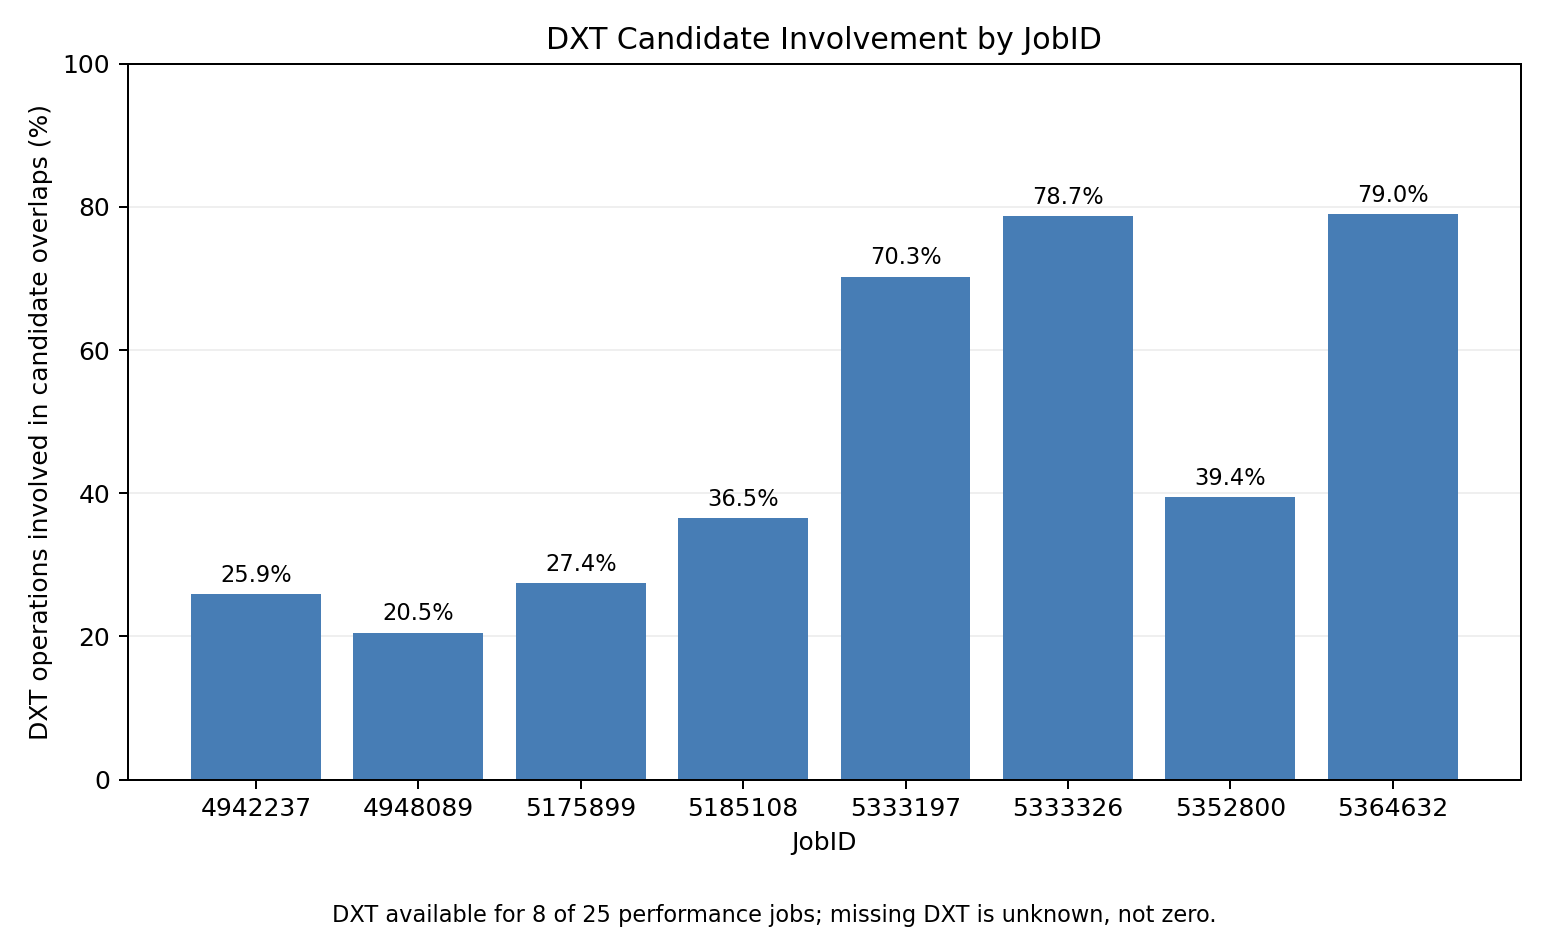

02_performance_of_dxt_covered_jobs.png


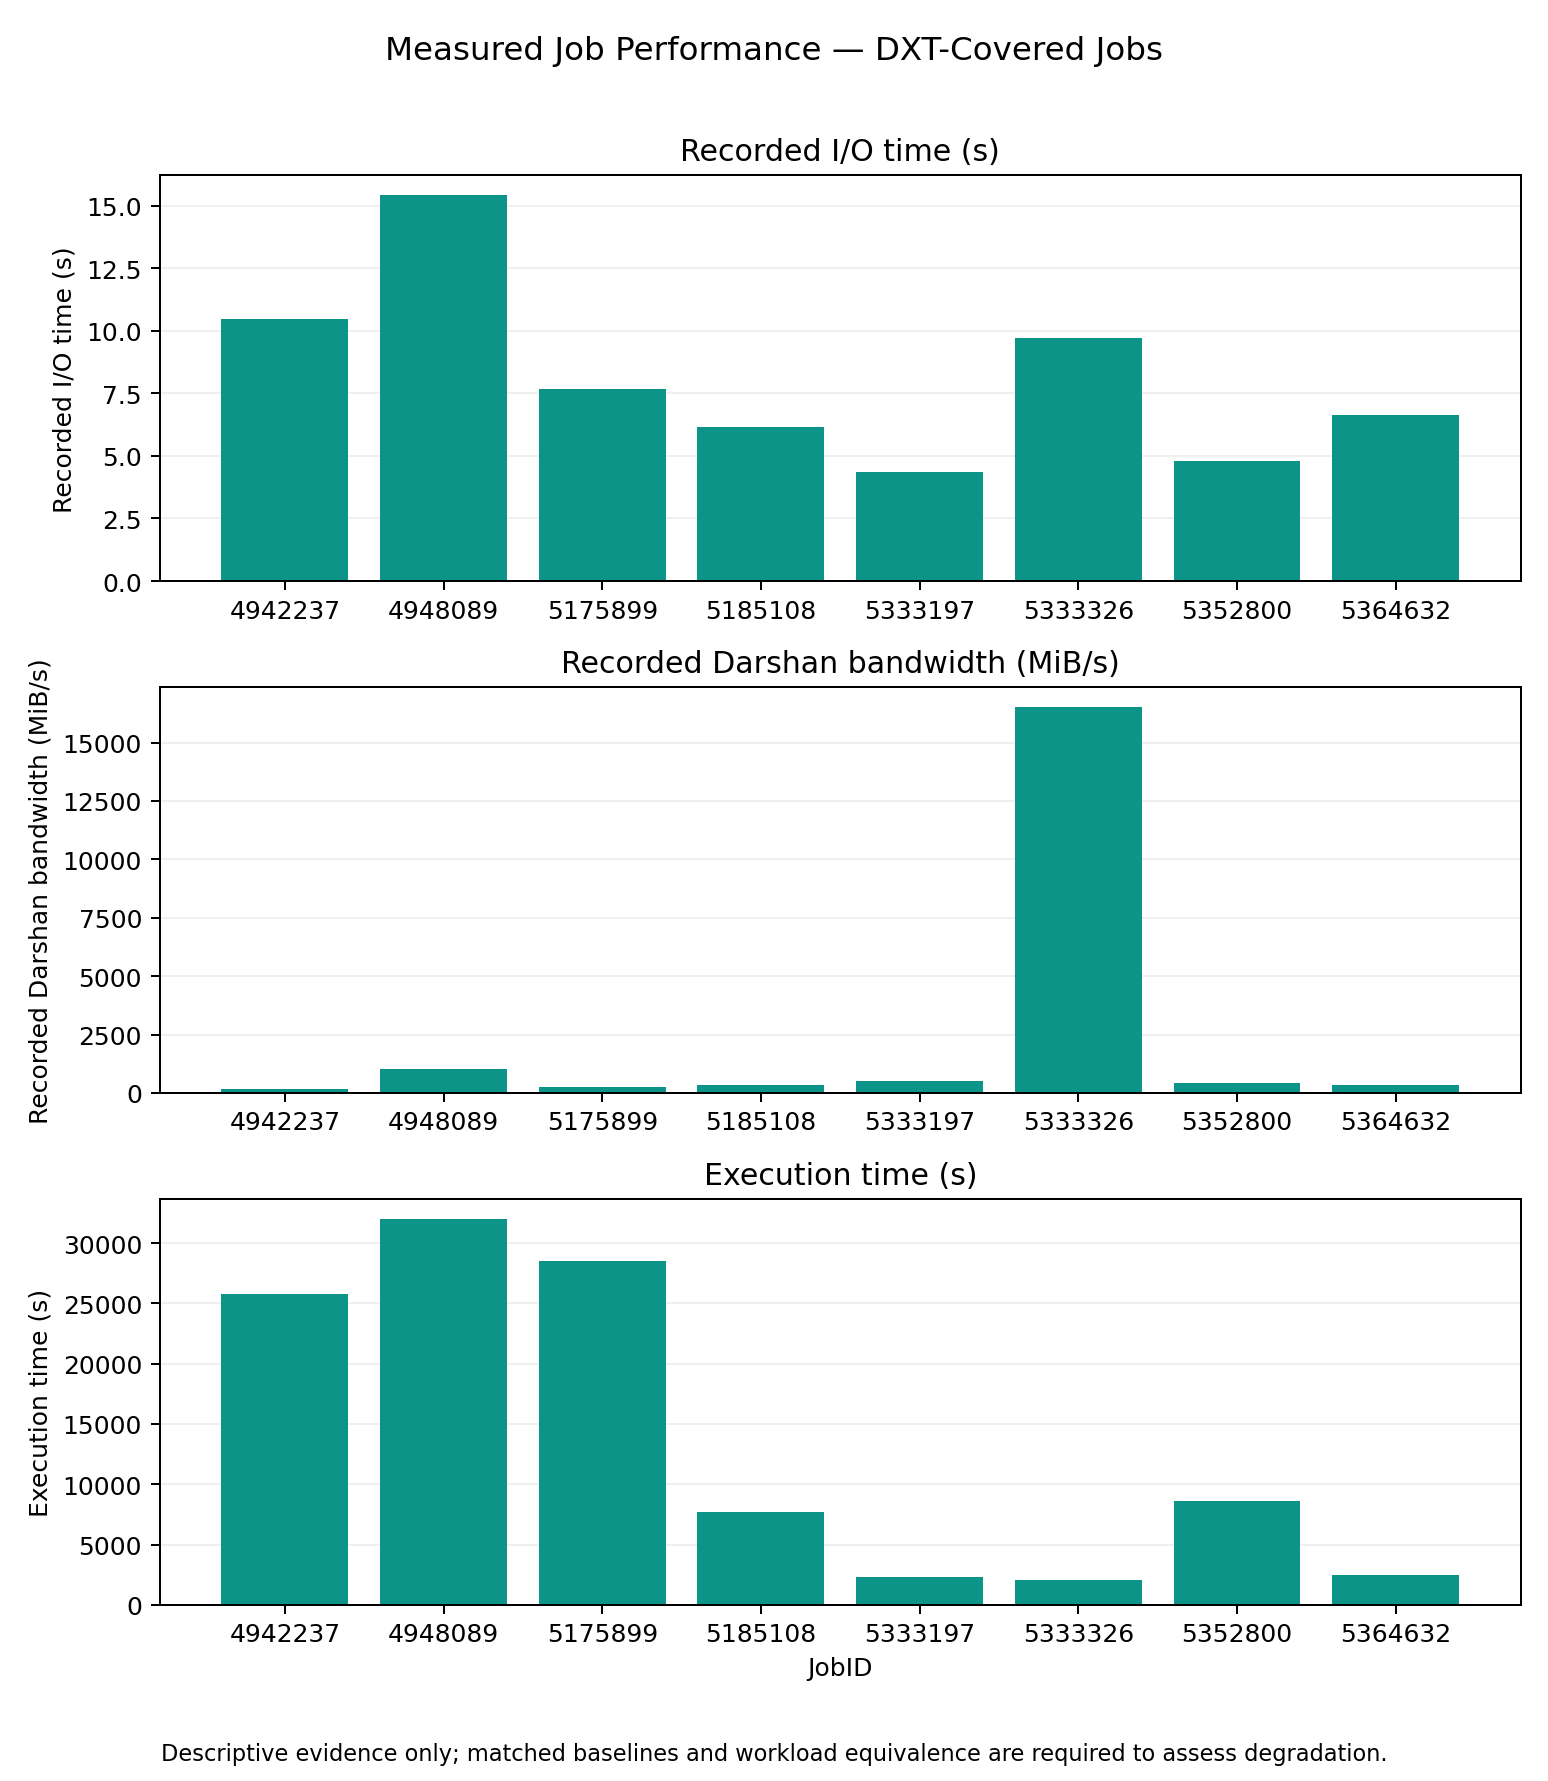

2A_bandwidth_mib_s_001.png


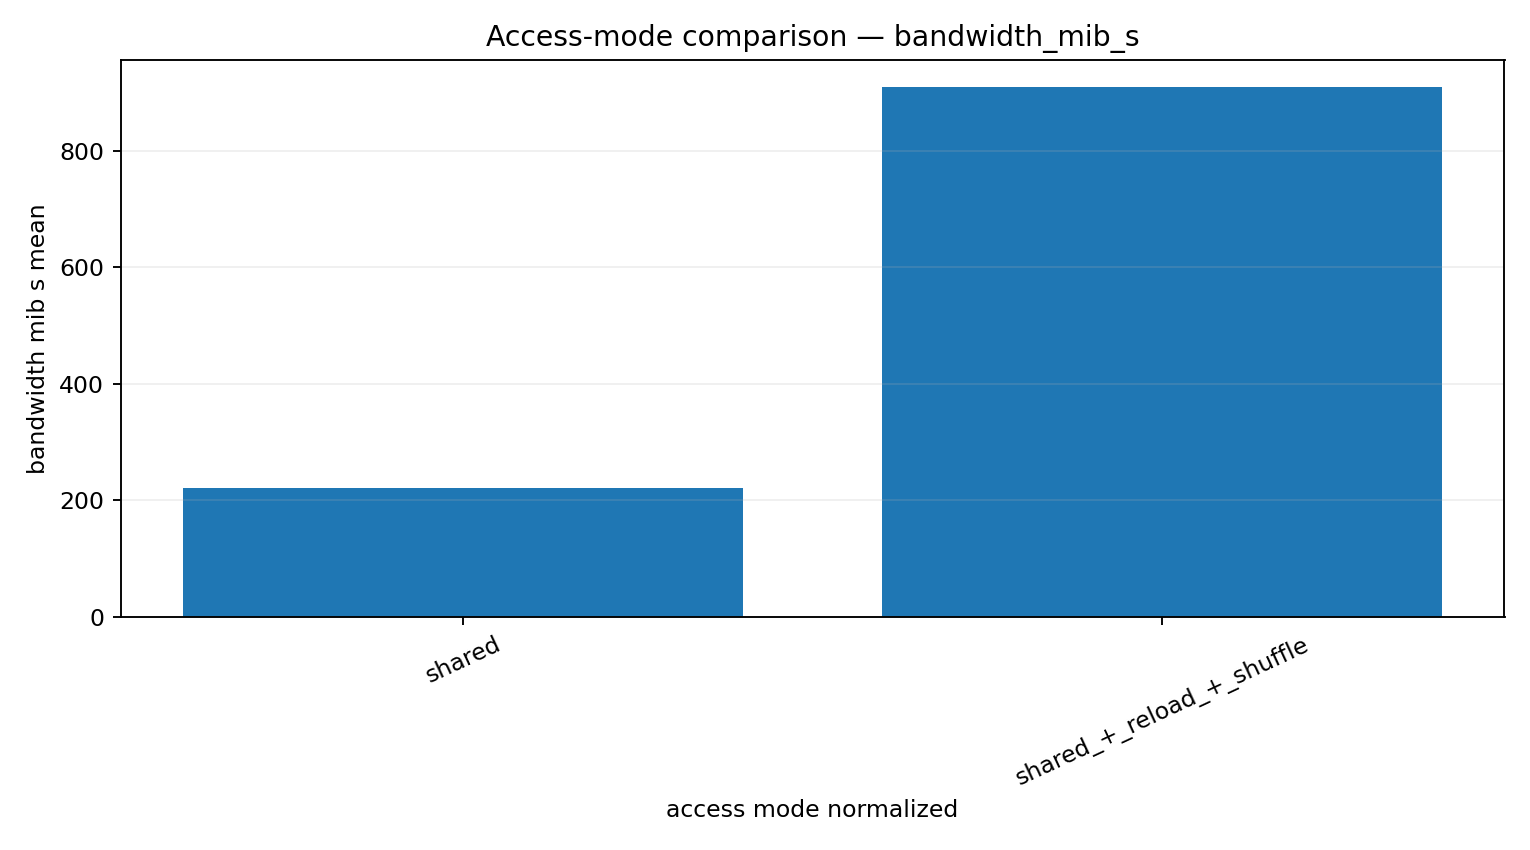

2A_bandwidth_mib_s_004.png


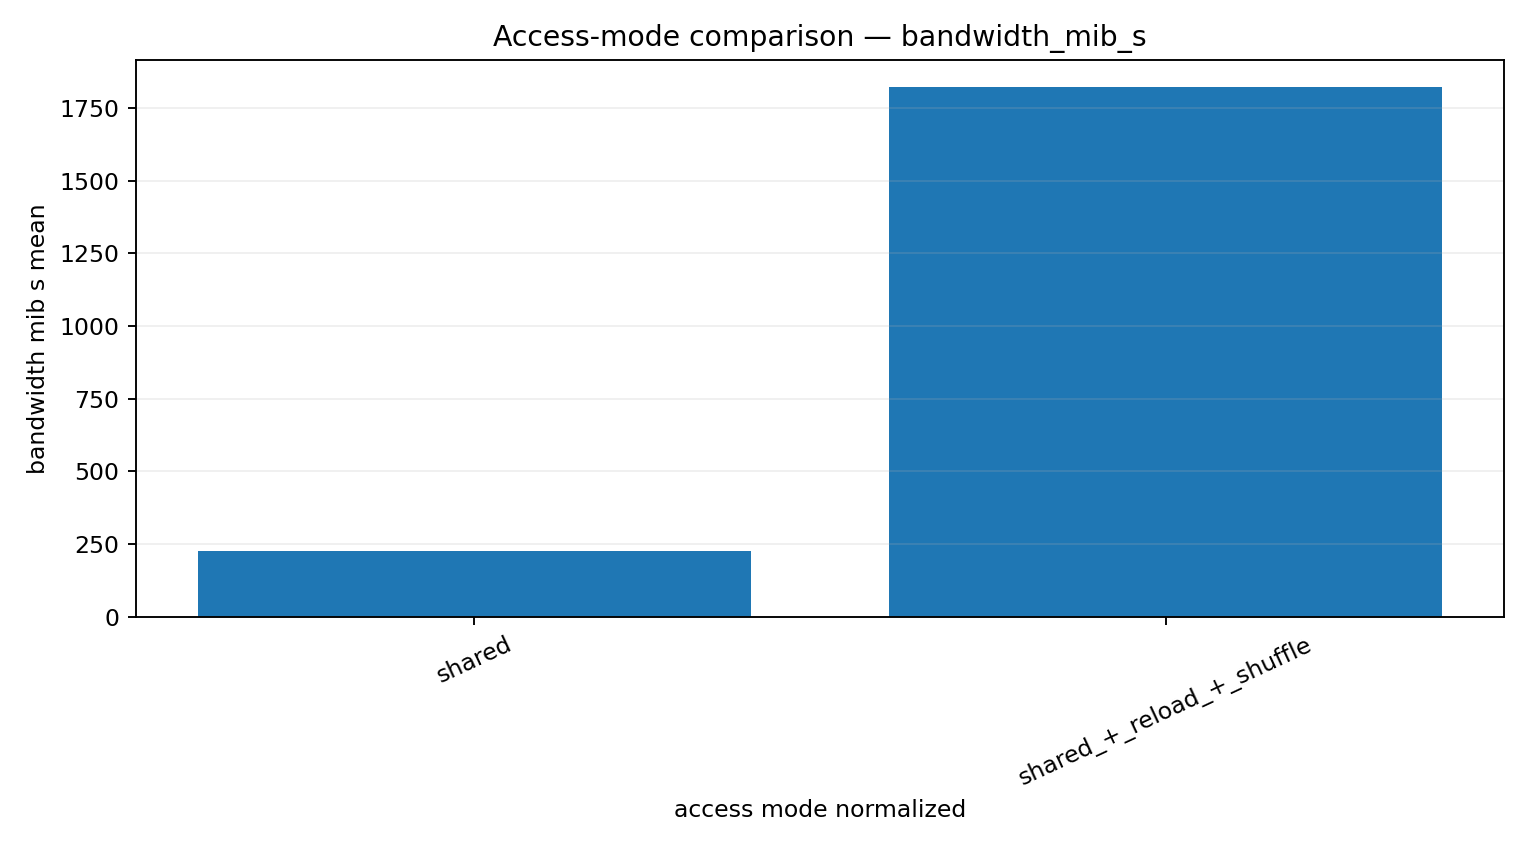

2A_bandwidth_mib_s_007.png


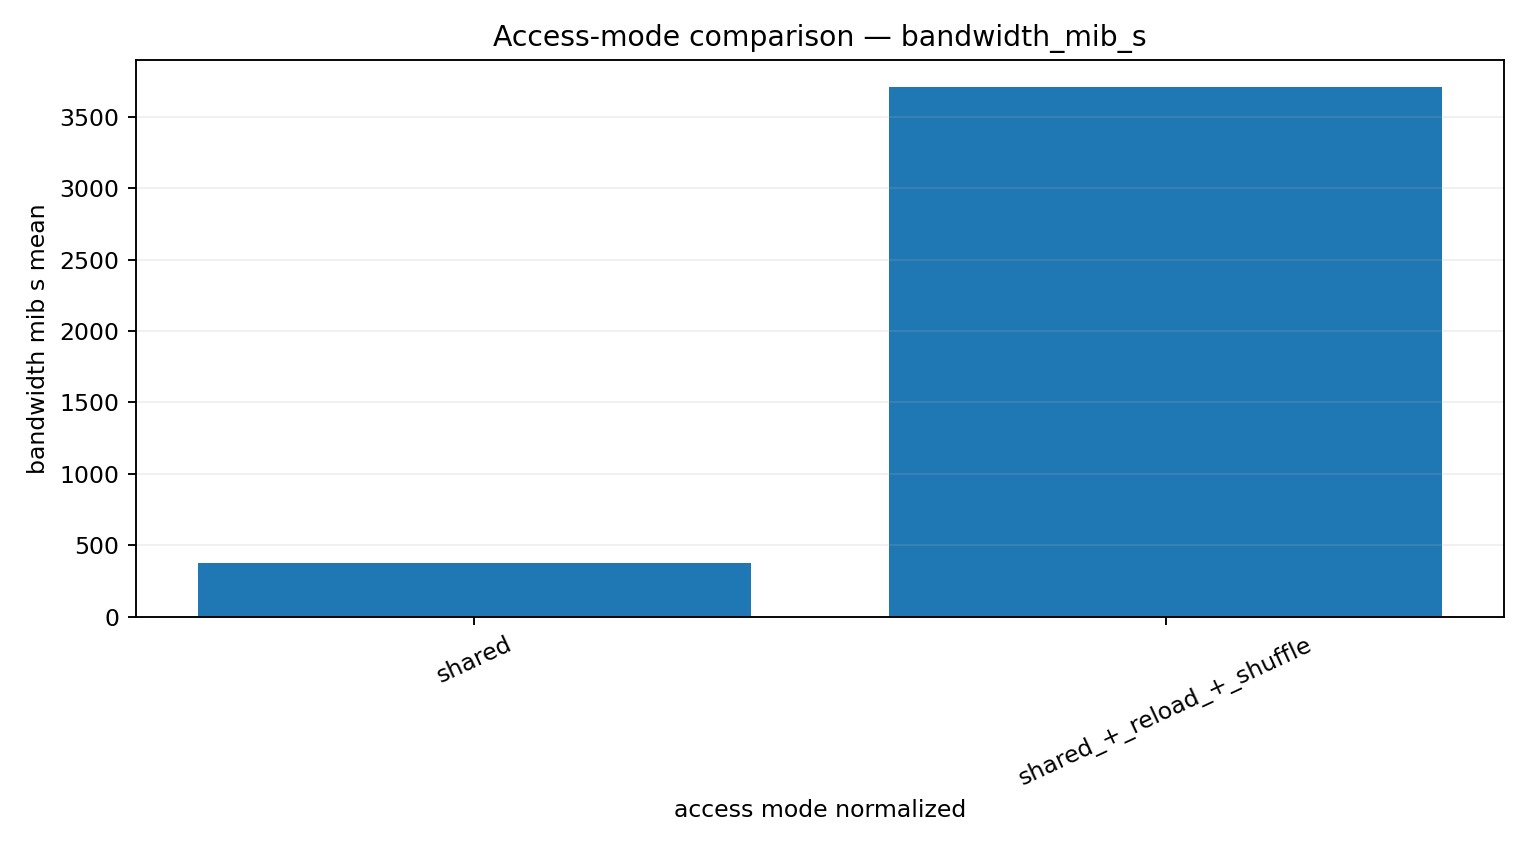

2A_bandwidth_mib_s_010.png


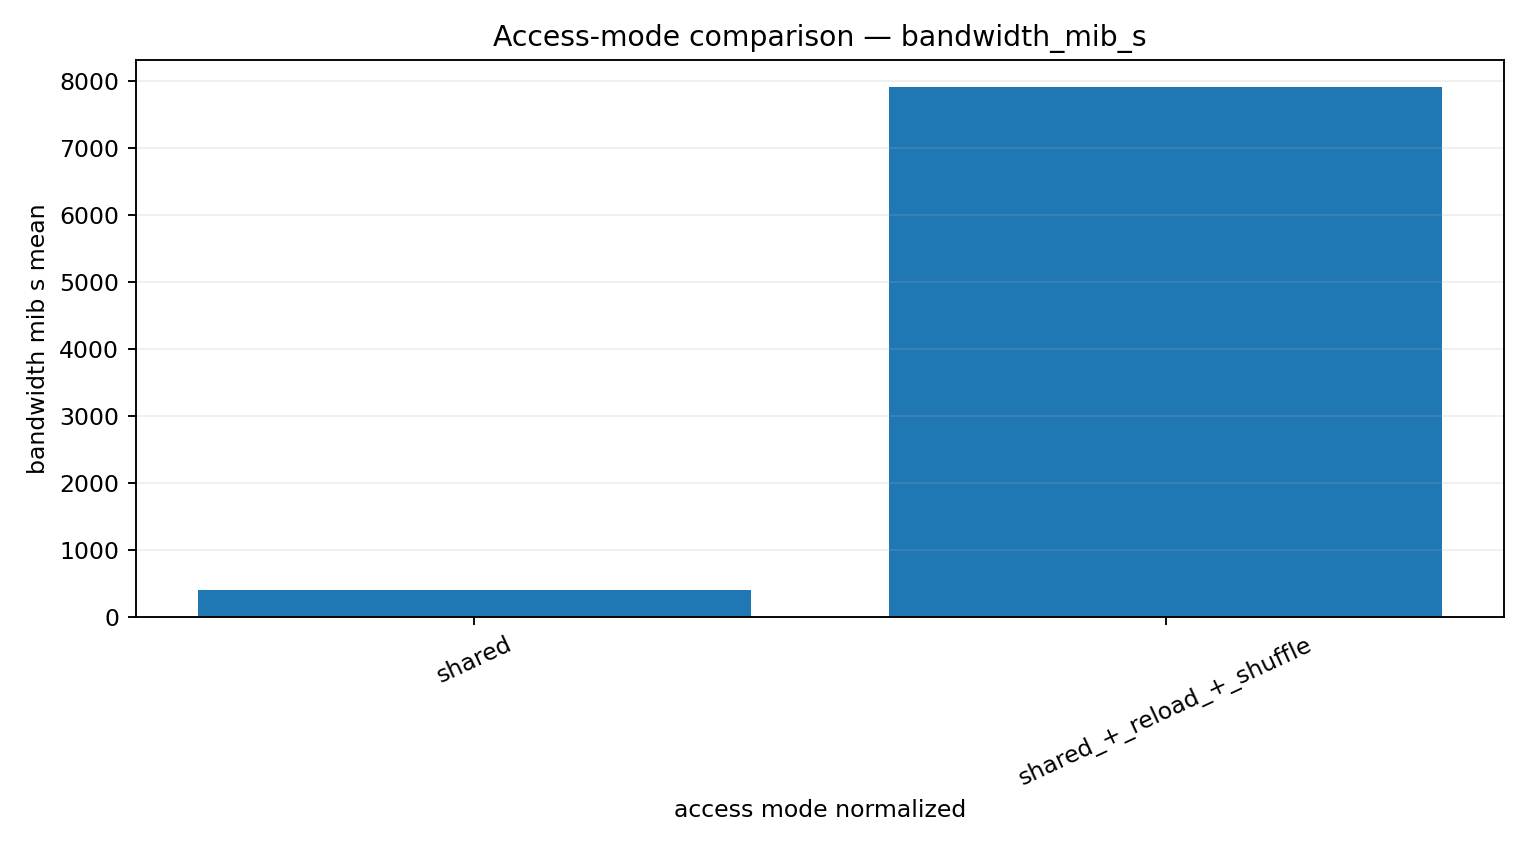

2A_bandwidth_mib_s_013.png


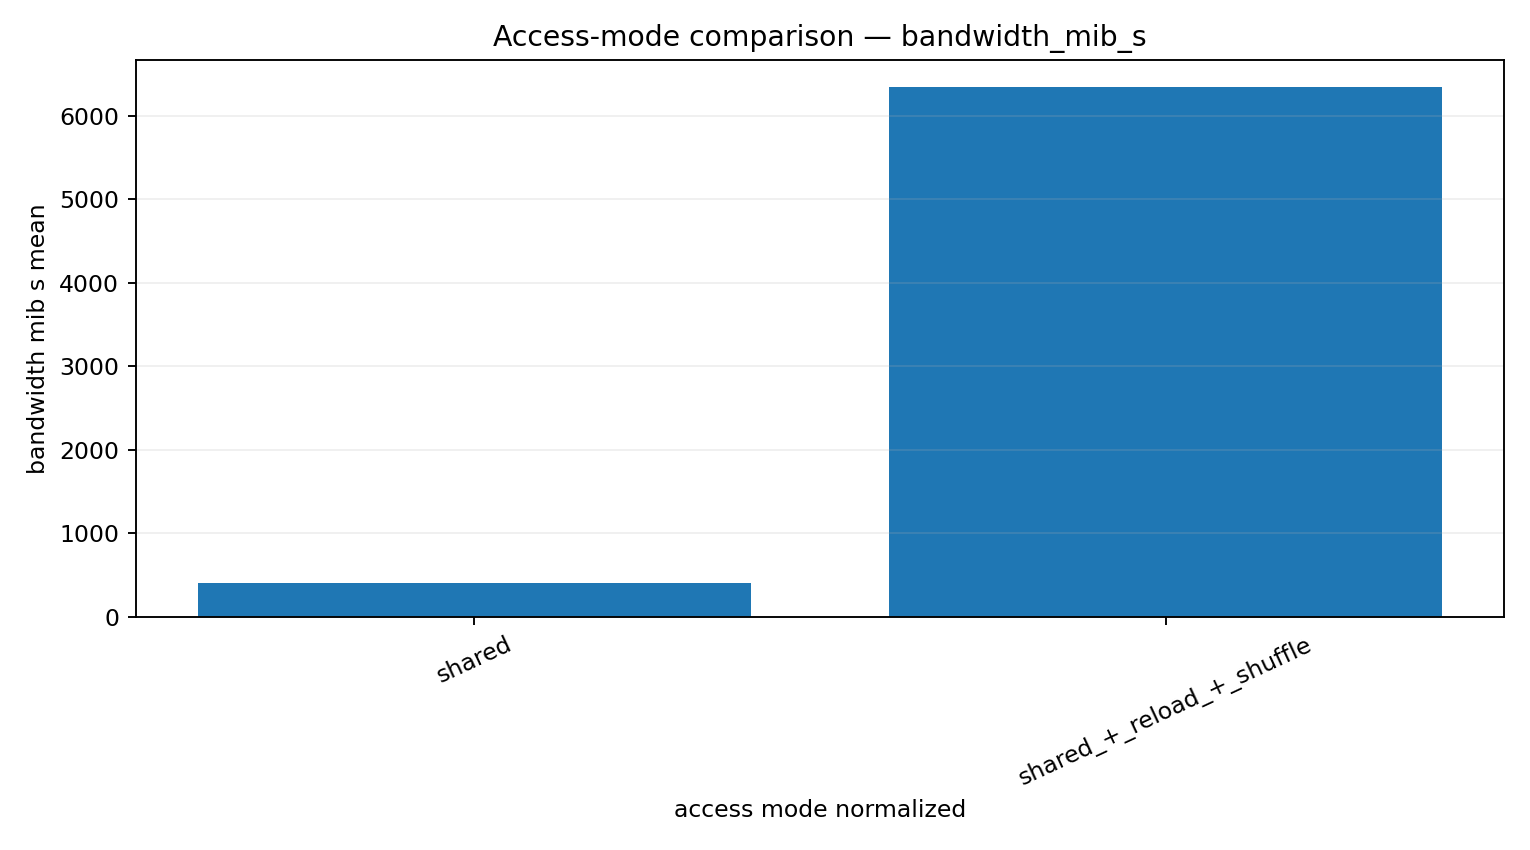

2A_bandwidth_mib_s_016.png


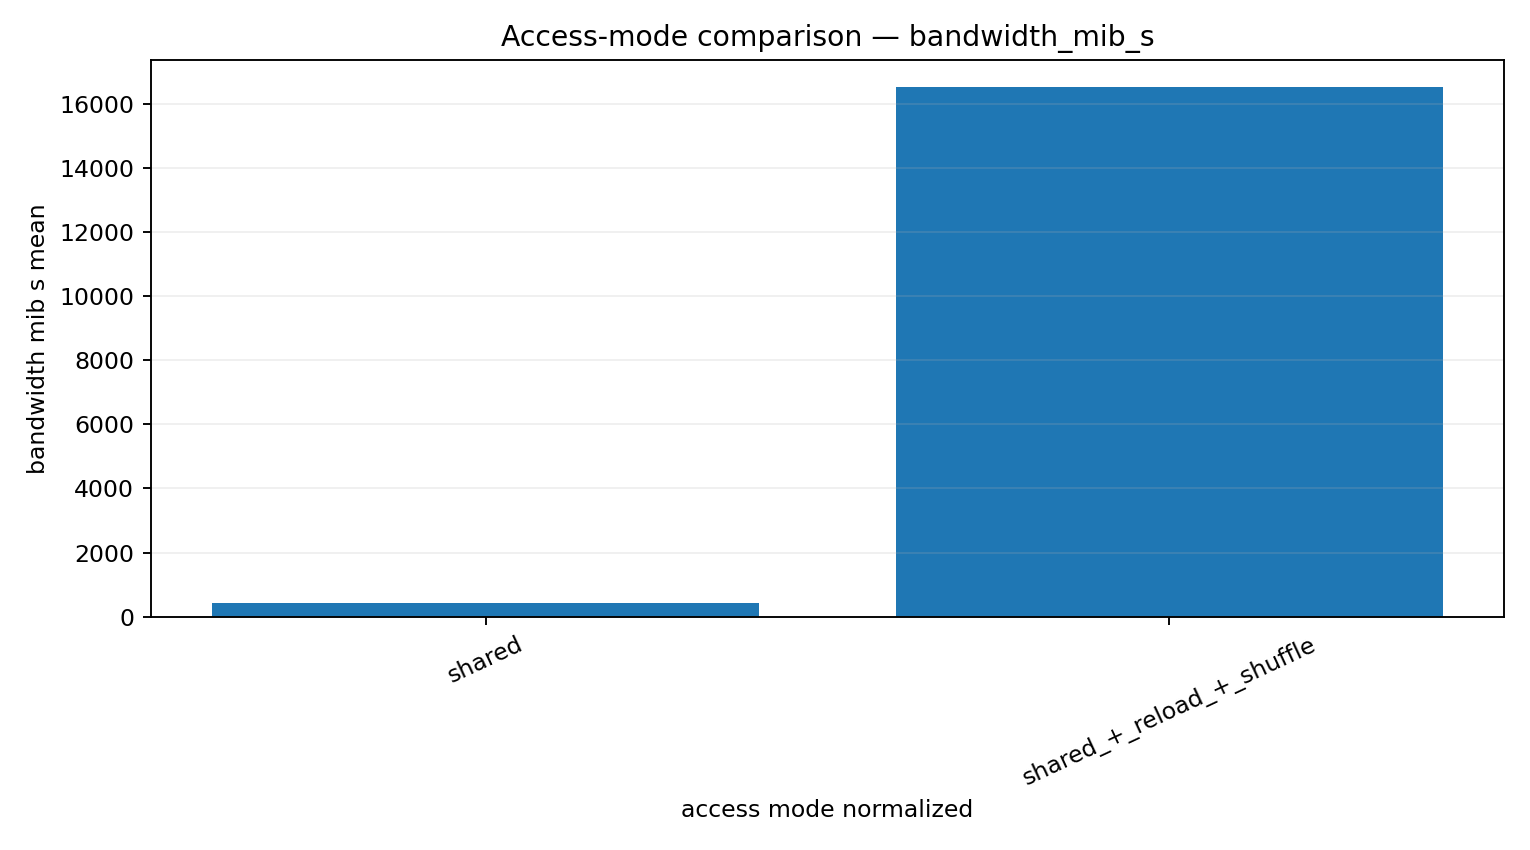

2A_bandwidth_mib_s_020.png


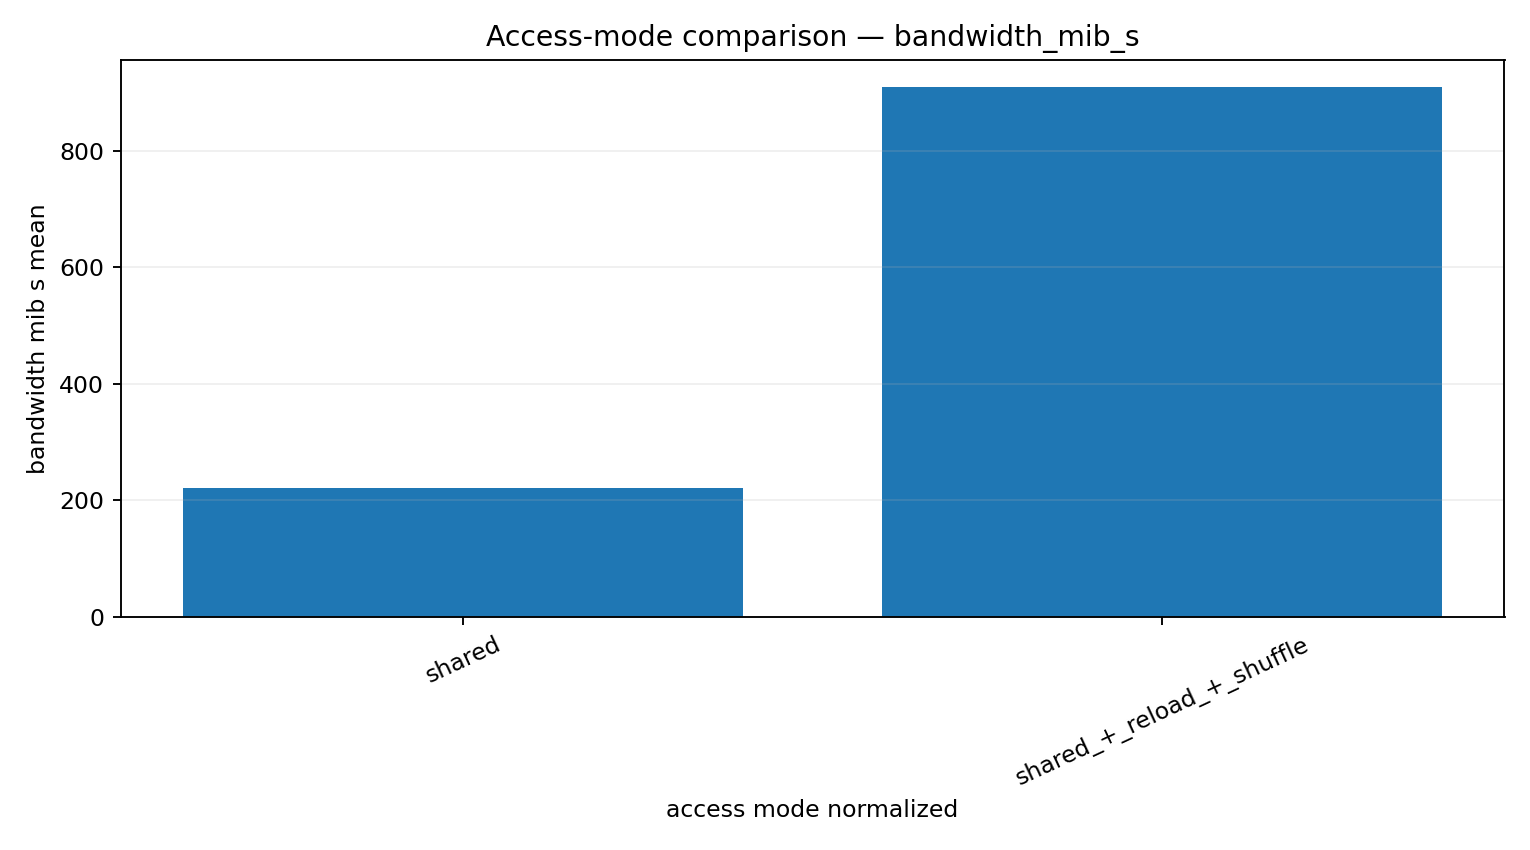

2A_bandwidth_mib_s_024.png


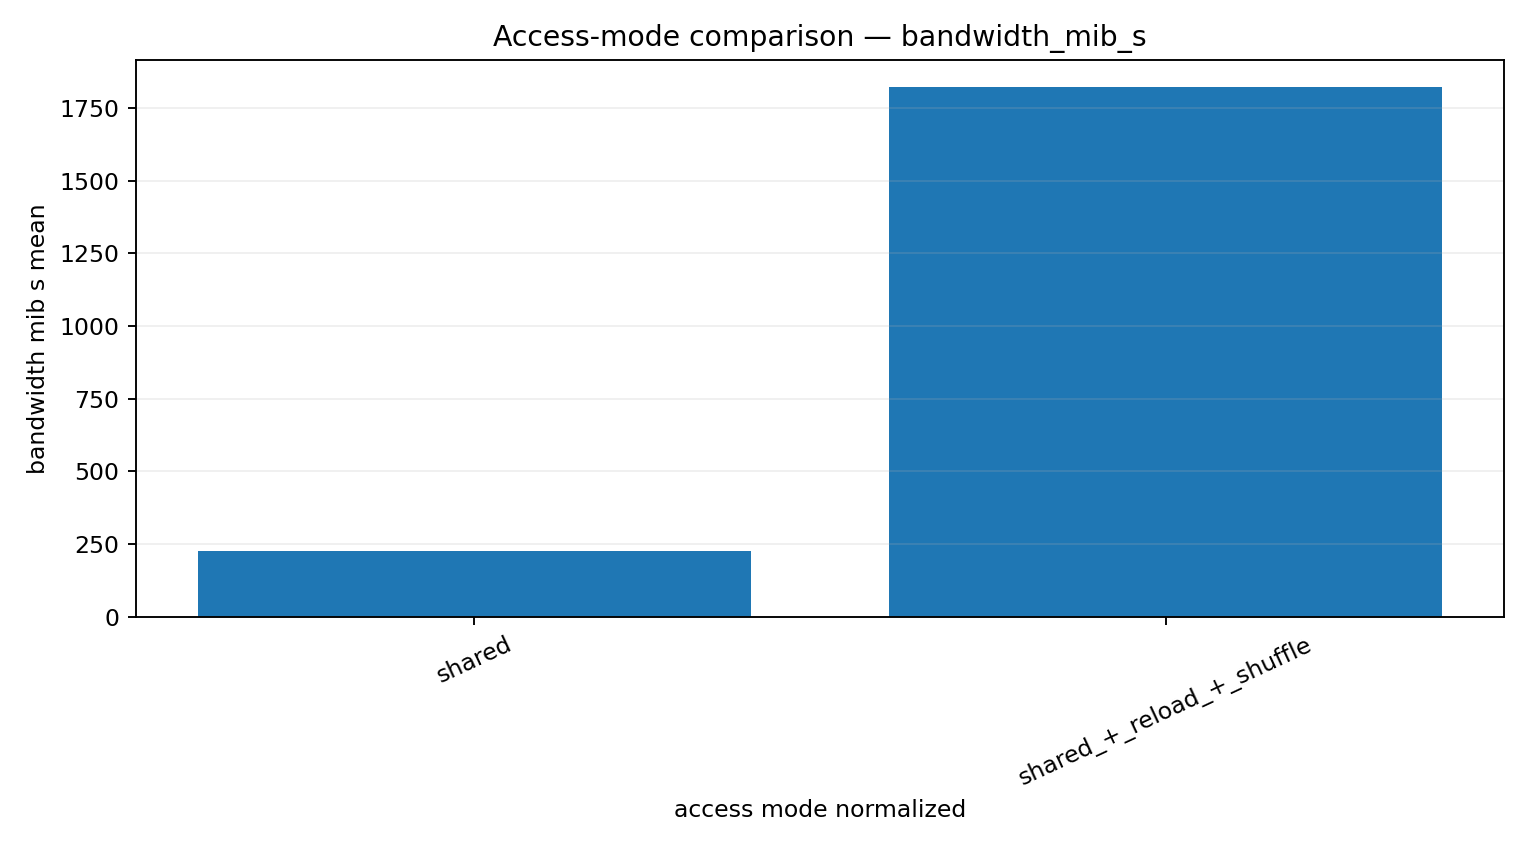

2A_bandwidth_mib_s_027.png


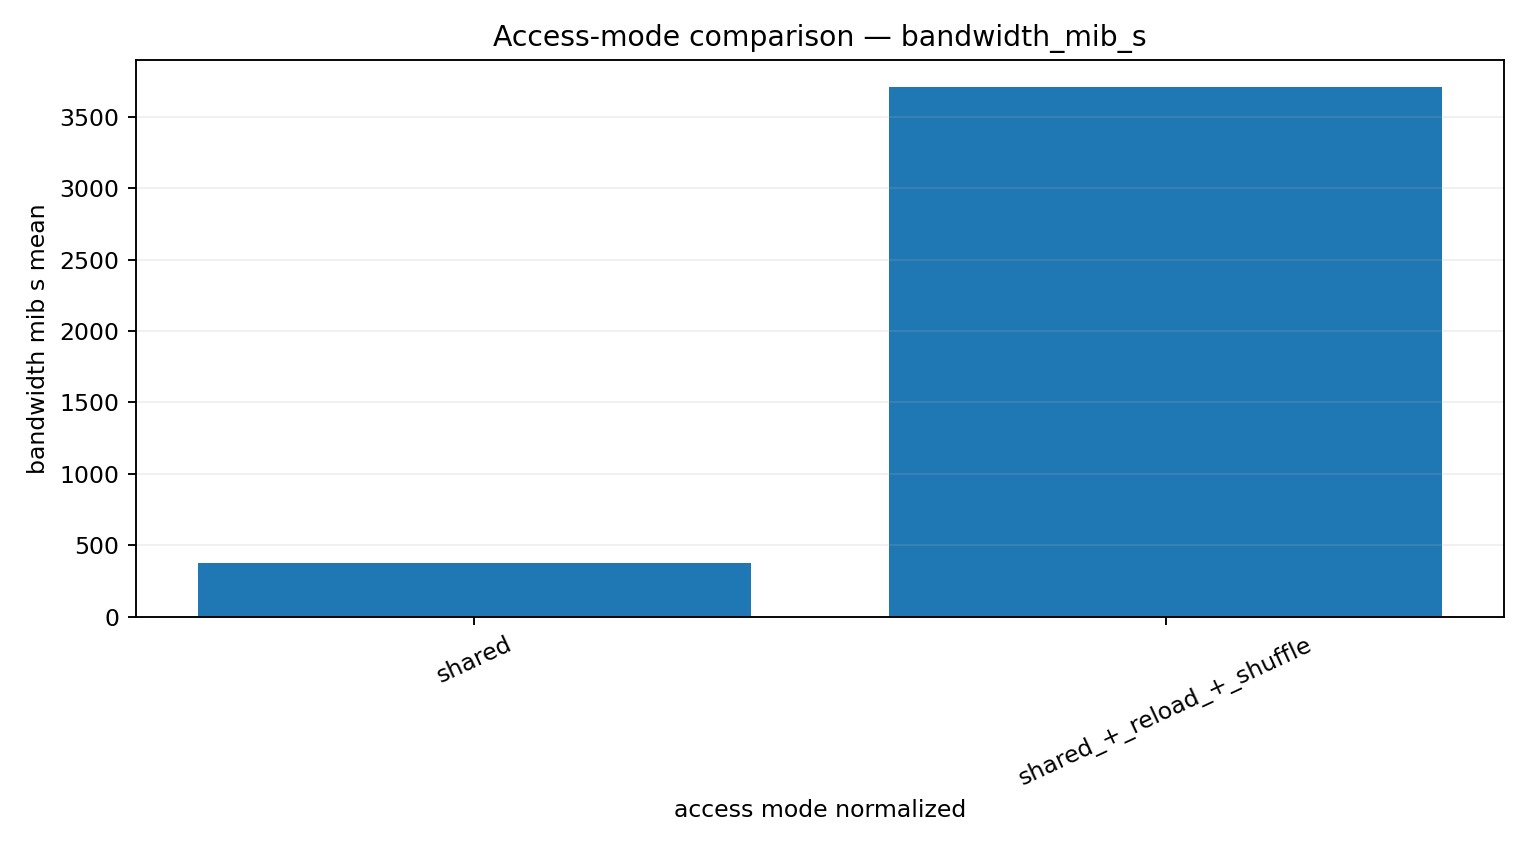

2A_bandwidth_mib_s_030.png


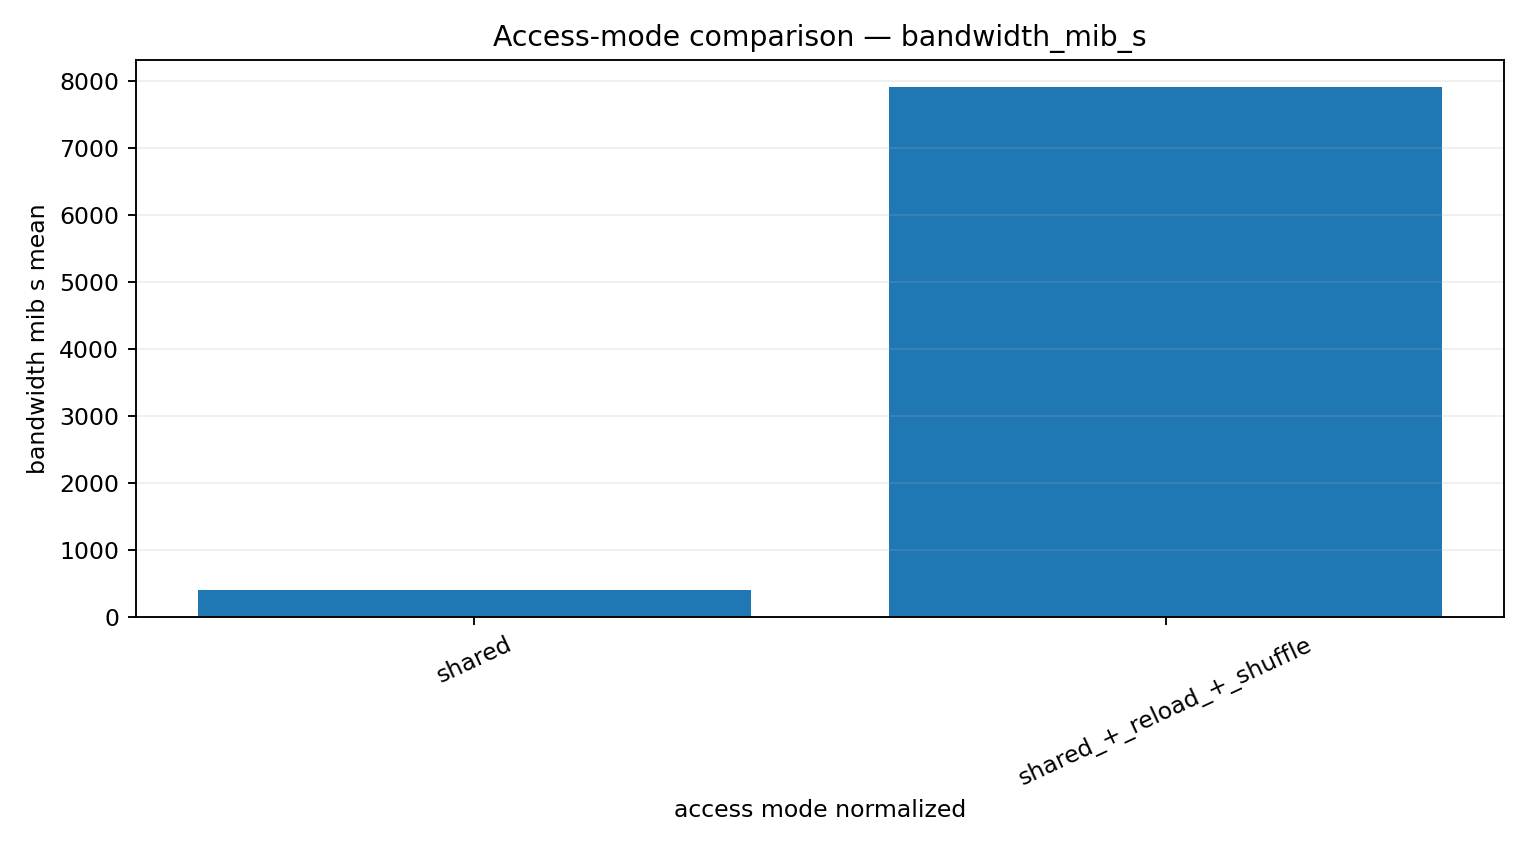

In [19]:
from IPython.display import Image
figures = sorted(OUTPUT_DIR.glob("01_dxt_*.png")) + sorted(OUTPUT_DIR.glob("02_performance_*.png")) + sorted(OUTPUT_DIR.glob("2A_*.png")) + sorted(OUTPUT_DIR.glob("2B_*.png"))
print("Figuras:", len(figures))
for fig in figures[:12]:
    print(fig.name)
    display(Image(filename=str(fig)))

## 9. Interpretación y validación científica

- **Nivel 1:** operaciones DXT con coincidencias espaciales o temporales; no afirmar ralentización.
- **Nivel 2A:** comparar modos de acceso bajo configuraciones equivalentes.
- **Nivel 2B:** estudiar escalabilidad dentro de cada modo.
- **Validación:** consultar `00_coverage_and_limitations.json`, cobertura DXT, ejecuciones truncadas y equivalencia de volumen de E/S, nodos, caché y sistema de archivos.
- **Evidencia causal:** requiere referencias comparables y, preferiblemente, repeticiones.

**Nota:** el análisis de un único JobID no basta para producir comparaciones 2A/2B.